**This version executes the machine learning analysis of the siver nanoparticles processing while uploading the cleaned file as well as processing it and giving the outputs depending on the applied model.** Version 1.0. Creators: Aura Ximena Gonzalez Cely

In [ ]:
import pandas as pd
import re
import numpy as np
#Classification model libraries
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
#Regression model libraries
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

#Evaluation libraries and plots
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt


In [ ]:
# Read Excel file
df = pd.read_excel("/content/Raw data.xlsx")

df_selec = df.iloc[:, 1:10] #Rows of interest
df_selec = df_selec.iloc[:57, :] # Columns of interest

# Verify
print("selection: ", df_selec.head())
print(df_selec.info())


selection:           pH Temperature (°C) Stirring time (min) Concentration extract (%)  \
0   7,0-9,0               34                  60                      3.47   
1  4,0-10,0            25-80              20-120                      5-20   
2   5,0-9,0            25-75               30-90                      5-15   
3   6,0-8,0            25-70               30-90                         5   
4   6,5-7,5            40-70                  60                         5   

       Plant type         Nanoparticle shape Nanoparticle size (nm)  \
0  Mandarin waste                  Spherical                  15-35   
1  Various plants  Spherical and anisotropic                   5-50   
2  Various plants  Spherical and anisotropic                  10-50   
3        Hibiscus    Spherical or aggregates                  20-70   
4        Hibiscus                  Spherical                  30-60   

  Zeta potential (mV)     Properties  
0           -25 a -35        Removal  
1           -2

In [ ]:
def separate_min_max(val):
    if pd.isna(val):
        return pd.Series([None, None])
    # Convert to string and replace comma per point
    val_str = str(val).replace(',', '.').strip()

    # Delete any character that is not a number, such as a point or a middle dash
    val_str = re.sub(r'[^0-9\.\-]', '', val_str)

    # Separate range of numbers whether there is a middle dash
    if '-' in val_str:
        parts = val_str.split('-')
        try:
            min_val = float(parts[0])
            max_val = float(parts[1])
        except ValueError:
            min_val = max_val = None
    else:
        try:
            min_val = max_val = float(val_str)
        except ValueError:
            min_val = max_val = None

    return pd.Series([min_val, max_val])

# Aplicar la función
column_pH = df_selec.iloc[:, 0] # pH
df_selec[['pH_min', 'pH_max']] = column_pH.apply(separate_min_max)

column_temp = df_selec.iloc[:, 1]  # temperature
df_selec[['temp_min', 'temp_max']] = column_temp.apply(separate_min_max)

column_stirr = df_selec.iloc[:, 2]  # stirring time
df_selec[['stirrtime_min', 'stirrtime_max']] = column_stirr.apply(separate_min_max)

column_extrac = df_selec.iloc[:, 3]  # extracto
df_selec[['extract_min', 'extract_max']] = column_extrac.apply(separate_min_max)

column_nanosize = df_selec.iloc[:, 6]  # tamano nanoparticula
df_selec[['nanosize_min', 'nanosize_max']] = column_nanosize.apply(separate_min_max)


In [ ]:
def separate_range(val):
    if pd.isna(val):
        return pd.Series([None, None])

    val_str = str(val).replace(',', '.').strip()

    # Look for the numbers, even if it's a negative value
    match = re.match(r'(-?\d+\.?\d*)\s*(?:-|a)\s*(-?\d+\.?\d*)', val_str)

    if match:
        min_val = float(match.group(1))
        max_val = float(match.group(2))
    else:
        try:
            min_val = max_val = float(val_str)
        except ValueError:
            min_val = max_val = None

    return pd.Series([min_val, max_val])

# Apply function

column_zetapot = df_selec.iloc[:, 7]  # zeta potential
df_selec[['zetapot_min', 'zetapot_max']] = column_zetapot.apply(separate_range)




In [ ]:

map_names = {
    "Antimicrobial": 1,
    "Antioxidant": 2,
    "Synthesis": 3,
    "Antibacterial": 4
}

# Select and map values of the nanoparticle shape
df_selec["Property"] = df_selec.iloc[:, 8].map(map_names)

counting_names = df_selec.iloc[:, 8].value_counts()
print("counting names: ", counting_names)
print(df_selec)

counting names:  Properties
Antimicrobial                        21
Synthesis                            15
Antibacterial                         7
Antioxidant                           4
Inhibition                            1
Removal                               1
Green applications                    1
Farmacology                           1
Environmental sensor                  1
Healing                               1
Biological activity                   1
Degradation                           1
Nanonutrient effect                   1
Optical and biological properties     1
Name: count, dtype: int64
          pH Temperature (°C) Stirring time (min) Concentration extract (%)  \
0    7,0-9,0               34                  60                      3.47   
1   4,0-10,0            25-80              20-120                      5-20   
2    5,0-9,0            25-75               30-90                      5-15   
3    6,0-8,0            25-70               30-90                     

Labels para la forma de la nanoparticula
1=Esférica, 2=Esférica y anisotrópica, 3=Esférica o aglomerados, 4=Anisotrópica, 5=Esférica o anisotrópica

In [ ]:
map_shape = {
    "Spherical": 1,
    "Spherical and anisotropic": 2,
    "Spherical or aggregates": 3,
    "Anisotropic": 4,
    "Spherical or anisotropic": 5,
    "Spherical and poligonal" : 6
}

# Select map shape from column [:,5]
df_selec["Shape"] = df_selec.iloc[:, 5].map(map_shape)

counting_names = df_selec.iloc[:, 5].value_counts()
print("counting_names: ", counting_names)
print(df_selec.head())

counting_names:  Nanoparticle shape
Spherical                    42
Spherical and anisotropic     4
Spherical and poligonal       4
Spherical or aggregates       2
Anisotropic                   2
Spherical or anisotropic      2
Spherical or anisotrophic     1
Name: count, dtype: int64
         pH Temperature (°C) Stirring time (min) Concentration extract (%)  \
0   7,0-9,0               34                  60                      3.47   
1  4,0-10,0            25-80              20-120                      5-20   
2   5,0-9,0            25-75               30-90                      5-15   
3   6,0-8,0            25-70               30-90                         5   
4   6,5-7,5            40-70                  60                         5   

       Plant type         Nanoparticle shape Nanoparticle size (nm)  \
0  Mandarin waste                  Spherical                  15-35   
1  Various plants  Spherical and anisotropic                   5-50   
2  Various plants  Spherical and

In [ ]:
map_type = {
    'Mandarin waste': 1,
    'Various plants': 2,
    'Hibiscus': 3,
    'Caralluma subulata': 4,
    'Tobaco': 5,
    'Fruit': 6,
    'Dioscorea bulbifera': 7,
    'Piper longum catkin': 8,
    'Lawsonia inermis': 9,
    'Capparis zeylanica': 10,
    'Medicinal plants': 11,
    'Sansevieria trifasciata': 12,
    'Biopolimers': 13,
    'Carambola': 14,
    'Camellia': 15,
    'Mangifera leaves': 16,
    'Vernoria leaves': 17,
    'Onion peel': 18,
    'Biosurfuctant': 19,
    'Solanum leaves': 20,
    'Cacao leaves': 21,
    'Moringa leaves': 22,
    'Azadirachta': 23,
    'Persea leaves': 24,
    'Croton roots': 25,
    'Coleus root': 26,
    'Lemon leaves': 27,
    'Banana peel': 28,
    'Tectona seeds': 29,
    'Olive leaves': 30,
    'Acalyoha leaves': 31,
    'Ficus benghalensis leaves': 32,
    'Litchi leaves': 33,
    'Salvia leaves': 34,
    'Orange waste': 35
}

df_selec["Plant types"] = df_selec.iloc[:, 4].map(map_type)
counting_names = df_selec.iloc[:, 4].value_counts(dropna=False)

print("counting_names:", counting_names)
print(df_selec.head())

counting_names: Plant type
Various plants               15
Hibiscus                      3
Sansevieria trifasciata       3
Caralluma subulata            2
Lemon leaves                  2
Non specified                 2
Mandarin waste                1
Fruit                         1
Piper longum catkin           1
Lawsonia inermis              1
Capparis zeylanica            1
Tobaco                        1
Medicinal plants              1
Biopolimers                   1
Carambola                     1
Camellia                      1
Mangifera leaves              1
Vernoria leaves               1
Onion peel                    1
Dioscorea bulbifera           1
Biosurfactant                 1
Solanum leaves                1
Moringa leaves                1
Cacao leaves                  1
Azadirachta                   1
Persea leaves                 1
Croton roots                  1
Coleus root                   1
Banana peel                   1
Tectona seeds                 1
Olive leaves 

In [ ]:
df_sub = df_selec.iloc[:, 9:24]

# Verify info
print(df_sub.head())
print(df_sub.shape)

# Normalization column by column
df_norm = df_sub.copy()

for col in df_norm.columns:
    col_mean = df_norm[col].mean(skipna=True)
    col_std = df_norm[col].std(skipna=True)
    df_norm[col] = (df_norm[col] - col_mean) / col_std

# Verify normalization
print("Normalized df: ",df_norm.head())

# DataFrame with rows that have at least one NaN value
df_nan = df_norm[df_norm.isna().any(axis=1)]

# DataFrame with rows without NaN values
df_no_nan = df_norm[df_norm.notna().all(axis=1)]
print(df_nan.shape, df_no_nan.shape)
print(df_no_nan.head())

# Mostrar las columnas relacionadas con Property
print("Columnas disponibles:")
print(df_sub.columns.tolist())

# Comparar valores originales y normalizados
for col in ["Property", "Properties"]:
    if col in df_sub.columns:
        comparison = pd.DataFrame({
            "Original": df_sub[col],
            "Normalized": df_norm[col]
        })

        comparison = comparison.drop_duplicates().sort_values("Original")

        print(f"\nMapping para {col}:")
        print(comparison.to_string(index=False))


   pH_min  pH_max  temp_min  temp_max  stirrtime_min  stirrtime_max  \
0     7.0     9.0      34.0      34.0           60.0           60.0   
1     4.0    10.0      25.0      80.0           20.0          120.0   
2     5.0     9.0      25.0      75.0           30.0           90.0   
3     6.0     8.0      25.0      70.0           30.0           90.0   
4     6.5     7.5      40.0      70.0           60.0           60.0   

   extract_min  extract_max  nanosize_min  nanosize_max  zetapot_min  \
0         3.47         3.47          15.0          35.0        -25.0   
1         5.00        20.00           5.0          50.0        -20.0   
2         5.00        15.00          10.0          50.0        -20.0   
3         5.00         5.00          20.0          70.0        -25.0   
4         5.00         5.00          30.0          60.0        -30.0   

   zetapot_max  Property  Shape  Plant types  
0        -35.0       NaN    1.0          1.0  
1        -40.0       1.0    2.0          2.0  

In [ ]:
"""
# Define target
target_col = "Property"

# Categorical class definition
Y = pd.Categorical(df_no_nan[target_col]).codes

# Delete target from the dataframe
X = df_no_nan.drop(columns=[target_col])

print("X data: ", X.columns.tolist())

# See the number of observations and features
print("X shape:", X.shape)

# Display the first five rows
print(X.head())

# Data replication to avoid unbalanced data
df_balanced = df_no_nan.copy()
df_balanced["Y"] = Y

classes = np.unique(Y)
maxCount = df_balanced["Y"].value_counts().max()

data_balanced = df_balanced.copy()

for c in classes:

    rows_class = df_balanced[df_balanced["Y"] == c]

    nRep = maxCount - len(rows_class)

    if nRep > 0:
        rows_add = rows_class.sample(n=nRep, replace=True, random_state=42)
        data_balanced = pd.concat([data_balanced, rows_add], ignore_index=True)

# Define final data and target
Y_bal = data_balanced["Y"].values
X_bal = data_balanced.drop(columns=[target_col, "Y"]).values

# Apply LeaveOneOut for validation
loo = LeaveOneOut()
predicciones = np.zeros(len(Y_bal))

for train_idx, test_idx in loo.split(X_bal):


    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale")
    ) #Model with data normalization

    model.fit(X_bal[train_idx], Y_bal[train_idx])

    predicciones[test_idx] = model.predict(X_bal[test_idx])


accuracy = accuracy_score(Y_bal, predicciones)
C = confusion_matrix(Y_bal, predicciones)
precision, recall, f1, _ = precision_recall_fscore_support(
    Y_bal,
    predicciones,
    average=None,
    zero_division=0
)

print(f"Accuracy LOOCV: {accuracy * 100:.2f}%")
print("Confusion Matrix:", C)
print("Results per class:")
for i in range(len(precision)):
    print(
        f"Class {i}: Precision={precision[i]:.2f}, "
        f"Recall={recall[i]:.2f}, F1={f1[i]:.2f}"
    )


print("Average Precision:", precision.mean())
print("Average Recall:", recall.mean())
print("Average F1:", f1.mean())
"""

X data:  ['pH_min', 'pH_max', 'temp_min', 'temp_max', 'stirrtime_min', 'stirrtime_max', 'extract_min', 'extract_max', 'nanosize_min', 'nanosize_max', 'zetapot_min', 'zetapot_max', 'Shape', 'Plant types']
X shape: (35, 14)
     pH_min    pH_max  temp_min  temp_max  stirrtime_min  stirrtime_max  \
1 -2.372530  2.625239 -0.597646  0.751268      -1.068460       0.897314   
2 -1.320942  1.475941 -0.597646  0.447994      -0.700259       0.080271   
3 -0.269354  0.326643 -0.597646  0.144720      -0.700259       0.080271   
4  0.256440 -0.248006  0.566334  0.144720       0.404342      -0.736772   
5  0.782234  0.326643 -0.209652 -0.461828       0.404342      -0.736772   

   extract_min  extract_max  nanosize_min  nanosize_max  zetapot_min  \
1    -0.371716     0.364069     -1.093151     -0.109627     0.576233   
2    -0.371716     0.007041     -0.610205     -0.109627     0.576233   
3    -0.371716    -0.707016      0.355685      1.126520    -0.505991   
4    -0.371716    -0.707016      1.3215

**Cross-validation analysis and stratified resampling within each training fold**

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneOut, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler


# --------------------------------------------------
# 1. Prepare the dataset
# --------------------------------------------------

target_col = "Property"

feature_cols = [
    col for col in df_no_nan.columns
    if col != target_col
]

data = df_no_nan.dropna(
    subset=[target_col] + feature_cols
).copy()

# Map the distinct target values to categorical labels.
# IMPORTANT: Use this only if the values represent
# genuine categories, not continuous measurements.
original_values = np.sort(data[target_col].unique())

value_to_class = {
    value: f"Class_{i+1}"
    for i, value in enumerate(original_values)
}

y = data[target_col].map(value_to_class).to_numpy()
X = data[feature_cols].to_numpy(dtype=float)

# Print feature names
print("X columns:", feature_cols)

# Number of observations and features
print("X shape:", X.shape)

# Display feature names with their indices
for i, col in enumerate(feature_cols):
    print(f"Feature {i}: {col}")

class_labels = [
    value_to_class[value] for value in original_values
]

print("Number of complete observations:", len(data))
print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())


# --------------------------------------------------
# 2. Define the pipeline
# --------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("oversampler", RandomOverSampler(random_state=42)),
    ("svm", SVC())
])


# --------------------------------------------------
# 3. Define candidate kernels and hyperparameters
# --------------------------------------------------

param_grid = [
    # Linear kernel
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },

    # Gaussian / RBF kernel
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1]
    },

    # Polynomial kernel
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
        "svm__degree": [2, 3],
        "svm__coef0": [0, 1]
    },

    # Sigmoid kernel
    {
        "svm__kernel": ["sigmoid"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
        "svm__coef0": [0, 1]
    }
]


# --------------------------------------------------
# 4. Nested leave-one-out cross-validation
# --------------------------------------------------

outer_cv = LeaveOneOut()

y_true = []
y_pred = []
selected_params = []
inner_best_scores = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Hyperparameter selection uses only the outer
    # training data.
    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "macro_f1": "f1_macro"
        },
        refit="balanced_accuracy",
        cv=inner_cv,
        n_jobs=-1,
        error_score="raise"
    )

    grid_search.fit(X_train, y_train)

    prediction = grid_search.predict(X_test)

    y_true.append(y_test[0])
    y_pred.append(prediction[0])
    selected_params.append(grid_search.best_params_)
    inner_best_scores.append(grid_search.best_score_)

    print(
        f"Fold {fold}/{len(X)} | "
        f"Kernel: {grid_search.best_params_['svm__kernel']} | "
        f"Best inner balanced accuracy: "
        f"{grid_search.best_score_:.3f}"
    )


# --------------------------------------------------
# 5. Evaluate outer-fold predictions
# --------------------------------------------------

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\n--- Nested LOOCV results ---")
print(f"Accuracy:          {accuracy_score(y_true, y_pred):.3f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_true, y_pred):.3f}"
)
print(
    f"Macro-F1:          "
    f"{f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}"
)

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=class_labels,
        zero_division=0
    )
)

print("Mapping between classes and original Property labels:")

for original_value, class_name in value_to_class.items():
    print(f"{class_name} = {original_value}")

print("Confusion matrix:")
print(
    pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=class_labels),
        index=[f"Actual_{c}" for c in class_labels],
        columns=[f"Predicted_{c}" for c in class_labels]
    )
)


# --------------------------------------------------
# 6. Summarize kernel and hyperparameter selection
# --------------------------------------------------

params_df = pd.DataFrame(selected_params)

print("\nKernel selection frequency:")
print(params_df["svm__kernel"].value_counts())

print("\nFull hyperparameter combination frequencies:")
print(params_df.value_counts().to_string())

print(
    "\nMean best inner-CV balanced accuracy "
    "(tuning score, not final performance): "
    f"{np.mean(inner_best_scores):.3f}"
)

X columns: ['pH_min', 'pH_max', 'temp_min', 'temp_max', 'stirrtime_min', 'stirrtime_max', 'extract_min', 'extract_max', 'nanosize_min', 'nanosize_max', 'zetapot_min', 'zetapot_max', 'Shape', 'Plant types']
X shape: (35, 14)
Feature 0: pH_min
Feature 1: pH_max
Feature 2: temp_min
Feature 3: temp_max
Feature 4: stirrtime_min
Feature 5: stirrtime_max
Feature 6: extract_min
Feature 7: extract_max
Feature 8: nanosize_min
Feature 9: nanosize_max
Feature 10: zetapot_min
Feature 11: zetapot_max
Feature 12: Shape
Feature 13: Plant types
Number of complete observations: 35

Class distribution:
Class_1    17
Class_2     4
Class_3     9
Class_4     5
Name: count, dtype: int64
Fold 1/35 | Kernel: sigmoid | Best inner balanced accuracy: 0.481
Fold 2/35 | Kernel: sigmoid | Best inner balanced accuracy: 0.464
Fold 3/35 | Kernel: rbf | Best inner balanced accuracy: 0.372
Fold 4/35 | Kernel: sigmoid | Best inner balanced accuracy: 0.372
Fold 5/35 | Kernel: sigmoid | Best inner balanced accuracy: 0.469
F

**Permutation test to assess classifier results**

Observed nested LOOCV balanced accuracy: 0.323
Permutation 1/19: balanced accuracy = 0.181
Permutation 2/19: balanced accuracy = 0.247
Permutation 3/19: balanced accuracy = 0.208
Permutation 4/19: balanced accuracy = 0.147
Permutation 5/19: balanced accuracy = 0.217
Permutation 6/19: balanced accuracy = 0.206
Permutation 7/19: balanced accuracy = 0.408
Permutation 8/19: balanced accuracy = 0.422
Permutation 9/19: balanced accuracy = 0.258
Permutation 10/19: balanced accuracy = 0.308
Permutation 11/19: balanced accuracy = 0.192
Permutation 12/19: balanced accuracy = 0.109
Permutation 13/19: balanced accuracy = 0.065
Permutation 14/19: balanced accuracy = 0.262
Permutation 15/19: balanced accuracy = 0.234
Permutation 16/19: balanced accuracy = 0.299
Permutation 17/19: balanced accuracy = 0.318
Permutation 18/19: balanced accuracy = 0.357
Permutation 19/19: balanced accuracy = 0.375

--- Permutation test results ---
Observed balanced accuracy: 0.323
Mean permuted balanced accuracy: 0.253


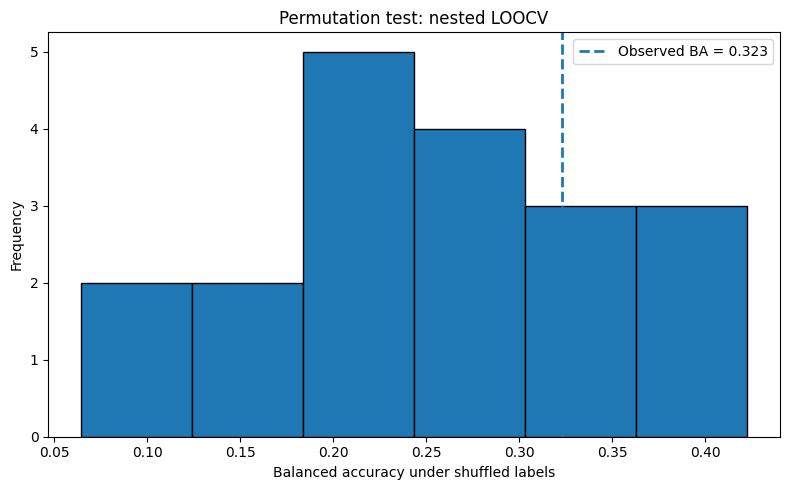

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneOut, StratifiedKFold, GridSearchCV
from sklearn.metrics import balanced_accuracy_score
from sklearn.svm import SVC

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler


# --------------------------------------------------
# 1. Define the same modeling pipeline
# --------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("oversampler", RandomOverSampler(random_state=42)),
    ("svm", SVC())
])

# Use the SAME param_grid as in your previous analysis.
# It should contain linear, rbf, poly, and sigmoid kernels.


# --------------------------------------------------
# 2. Function to rerun the entire nested LOOCV
# --------------------------------------------------

def nested_loocv_balanced_accuracy(X, y, param_grid):
    outer_cv = LeaveOneOut()

    y_true = []
    y_pred = []

    for train_idx, test_idx in outer_cv.split(X, y):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        inner_cv = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=42
        )

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="balanced_accuracy",
            refit=True,
            cv=inner_cv,
            n_jobs=-1,
            error_score="raise"
        )

        grid_search.fit(X_train, y_train)
        prediction = grid_search.predict(X_test)

        y_true.append(y_test[0])
        y_pred.append(prediction[0])

    return balanced_accuracy_score(y_true, y_pred)


# --------------------------------------------------
# 3. Calculate the observed statistic
# --------------------------------------------------

observed_ba = nested_loocv_balanced_accuracy(
    X, y, param_grid
)

print(f"Observed nested LOOCV balanced accuracy: {observed_ba:.3f}")


# --------------------------------------------------
# 4. Permutation test
# --------------------------------------------------

# Start with 99 permutations to check runtime.
# For a more stable final p-value, use 999 or more
# if computational resources allow.

n_permutations = 19
rng = np.random.default_rng(2026)

permutation_scores = []

for i in range(n_permutations):
    # Shuffle labels across observations.
    # This preserves the number of observations per class.
    y_permuted = rng.permutation(y)

    # Rerun all outer folds and inner model selection.
    permuted_ba = nested_loocv_balanced_accuracy(
        X, y_permuted, param_grid
    )

    permutation_scores.append(permuted_ba)

    print(
        f"Permutation {i + 1}/{n_permutations}: "
        f"balanced accuracy = {permuted_ba:.3f}"
    )


# --------------------------------------------------
# 5. Calculate the one-sided permutation p-value
# --------------------------------------------------

permutation_scores = np.asarray(permutation_scores)

# Add-one correction prevents a p-value of zero.
n_at_least_observed = np.sum(
    permutation_scores >= observed_ba
)

p_value = (
    1 + n_at_least_observed
) / (
    n_permutations + 1
)

print("\n--- Permutation test results ---")
print(f"Observed balanced accuracy: {observed_ba:.3f}")
print(f"Mean permuted balanced accuracy: {permutation_scores.mean():.3f}")
print(f"SD of permuted scores: {permutation_scores.std(ddof=1):.3f}")
print(f"95th percentile of null scores: {np.percentile(permutation_scores, 95):.3f}")
print(f"Permutations >= observed: {n_at_least_observed}/{n_permutations}")
print(f"One-sided permutation p-value: {p_value:.4f}")


# --------------------------------------------------
# 6. Plot the null distribution
# --------------------------------------------------

plt.figure(figsize=(8, 5))
plt.hist(
    permutation_scores,
    bins="auto",
    edgecolor="black"
)
plt.axvline(
    observed_ba,
    linestyle="--",
    linewidth=2,
    label=f"Observed BA = {observed_ba:.3f}"
)
plt.xlabel("Balanced accuracy under shuffled labels")
plt.ylabel("Frequency")
plt.title("Permutation test: nested LOOCV")
plt.legend()
plt.tight_layout()
plt.show()


**Regressor models code**

In [ ]:
# Linear Regressor nanosize min y nanosize max
df = df_no_nan

# Define output columns (targets)
target_cols = ["nanosize_min", "nanosize_max"]

# Outputs: the two columns you want to predict
y = df[target_cols].values

# Inputs: all remaining columns except the targets
X_df = df.drop(columns=target_cols)

# Keep feature names for inspection
feature_cols = X_df.columns.tolist()

# Convert inputs to NumPy arrays if needed
X = X_df.to_numpy(dtype=float)

print("Input features (X):")
for col in feature_cols:
    print(col)

print("\nOutput targets (y):")
print(target_cols)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

# Applying LeaveOneOut validation
loo = LeaveOneOut()
model = LinearRegression()
errors = []

for train_idx, test_idx in loo.split(X):  # Separating training and test data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    model.fit(X_train, y_train)   #Training the model
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    errors.append(mse)

# Average RMSE
rmse = np.sqrt(np.mean(errors))
print(f"Average RMSE (Leave-One-Out): {rmse:.4f}")


Input features (X):
pH_min
pH_max
temp_min
temp_max
stirrtime_min
stirrtime_max
extract_min
extract_max
zetapot_min
zetapot_max
Property
Shape
Plant types

Output targets (y):
['nanosize_min', 'nanosize_max']

X shape: (35, 13)
y shape: (35, 2)
Average RMSE (Leave-One-Out): 1.6544


In [ ]:
# Random Forest Regressor with hyperparameters selection
df = df_no_nan

# Define output columns (targets)
target_cols = ["nanosize_min", "nanosize_max"]

# Outputs: the two columns you want to predict
y = df[target_cols].values

# Inputs: all remaining columns except the targets
X_df = df.drop(columns=target_cols)

# Keep feature names for inspection
feature_cols = X_df.columns.tolist()

# Convert inputs to NumPy arrays if needed
X = X_df.to_numpy(dtype=float)

# Leave-One-Out cross-validation
loo = LeaveOneOut()

# Hyperparameters to test
n_estimators_list = [100, 200]
max_depth_list = [None, 5, 10, 20]
min_samples_split_list = [2, 5, 10]

# Store results
results = []

for n_estimators in n_estimators_list:

    for max_depth in max_depth_list:

        for min_samples_split in min_samples_split_list:

            errors_per_target = []

            print(f"Testing n_estimators: ", n_estimators)
            print(f"max_depth: ", max_depth)

            # Leave-One-Out loop
            for train_idx, test_idx in loo.split(X):

                # Split data
                X_train, X_test = X[train_idx], X[test_idx]
                y_train, y_test = y[train_idx], y[test_idx]

                # Predictions container
                y_pred = np.zeros_like(y_test, dtype=float)

                # Train one RF per target
                for i in range(y.shape[1]):

                    rf = RandomForestRegressor(
                        n_estimators=n_estimators,
                        max_depth=max_depth,
                        min_samples_split=min_samples_split,
                        random_state=42,
                        n_jobs=-1
                    )

                    rf.fit(X_train, y_train[:, i])

                    y_pred[:, i] = rf.predict(X_test)

                # Squared error
                errors_per_target.append((y_test - y_pred) ** 2)

            errors_per_target = np.array(errors_per_target)

            rmse_per_target = np.sqrt(
                np.mean(errors_per_target, axis=0)
            ).flatten()

            rmse_average = np.mean(rmse_per_target)

            # Save result
            results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "min_samples_split": min_samples_split,
                "rmse_target_1": rmse_per_target[0],
                "rmse_target_2": rmse_per_target[1],
                "rmse_average": rmse_average
            })

best_result = min(results, key=lambda x: x["rmse_average"])

print(f"best n_estimators : {best_result['n_estimators']}")
print(f"best max_depth    : {best_result['max_depth']}")
print(f"best min_samples_split : {best_result['min_samples_split']}")

print(f"RMSE target 1: {best_result['rmse_target_1']:.4f}")
print(f"RMSE target 2: {best_result['rmse_target_2']:.4f}")
print(f"Average RMSE : {best_result['rmse_average']:.4f}")

Testing n_estimators:  100
max_depth:  None
Testing n_estimators:  100
max_depth:  None
Testing n_estimators:  100
max_depth:  None
Testing n_estimators:  100
max_depth:  5
Testing n_estimators:  100
max_depth:  5
Testing n_estimators:  100
max_depth:  5
Testing n_estimators:  100
max_depth:  10
Testing n_estimators:  100
max_depth:  10
Testing n_estimators:  100
max_depth:  10
Testing n_estimators:  100
max_depth:  20
Testing n_estimators:  100
max_depth:  20
Testing n_estimators:  100
max_depth:  20
Testing n_estimators:  200
max_depth:  None
Testing n_estimators:  200
max_depth:  None
Testing n_estimators:  200
max_depth:  None
Testing n_estimators:  200
max_depth:  5
Testing n_estimators:  200
max_depth:  5
Testing n_estimators:  200
max_depth:  5
Testing n_estimators:  200
max_depth:  10
Testing n_estimators:  200
max_depth:  10
Testing n_estimators:  200
max_depth:  10
Testing n_estimators:  200
max_depth:  20
Testing n_estimators:  200
max_depth:  20
Testing n_estimators:  200
m

In [ ]:
df = df_no_nan

# Define output columns (targets)
target_cols = ["nanosize_min", "nanosize_max"]

# Outputs: the two columns you want to predict
y = df[target_cols].values

# Inputs: all remaining columns except the targets
X_df = df.drop(columns=target_cols)

# Keep feature names for inspection
feature_cols = X_df.columns.tolist()

# Convert inputs to NumPy arrays if needed
X = X_df.to_numpy(dtype=float)

print("Input features (X):")
for col in feature_cols:
    print(col)

print("\nOutput targets (y):")
print(target_cols)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Input features (X):
pH_min
pH_max
temp_min
temp_max
stirrtime_min
stirrtime_max
extract_min
extract_max
zetapot_min
zetapot_max
Property
Shape
Plant types

Output targets (y):
['nanosize_min', 'nanosize_max']

X shape: (35, 13)
y shape: (35, 2)


Optimized RandomForest RMSE:
  Min: 1.2143
  Max: 1.0055
  Mean: 1.1099


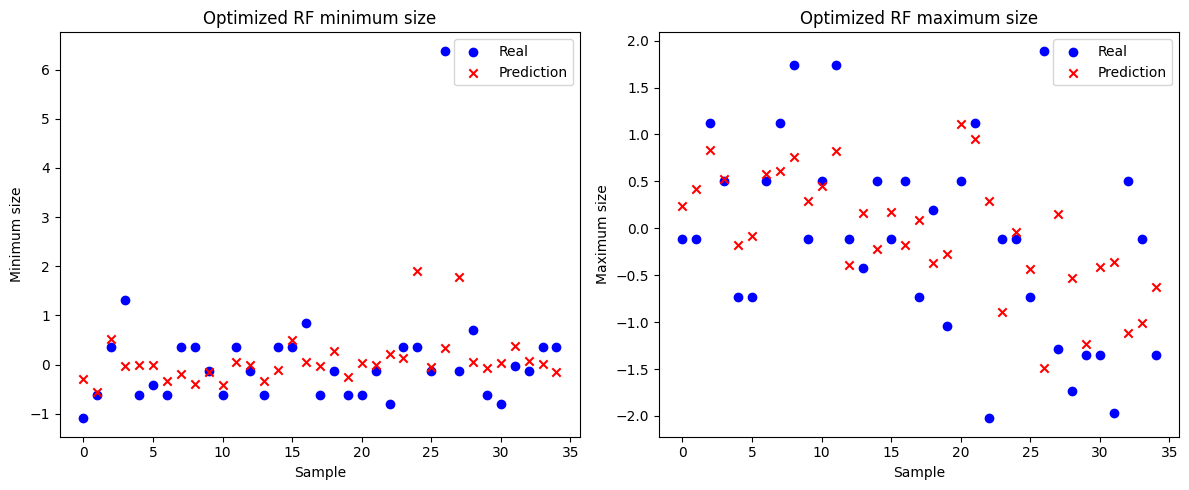

In [ ]:
#Training RF model considering the best hyperparameter from the previous code

# Best hyperparameters previously found
best_params = {
    'mínimo': {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 2},
    'máximo': {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 2}
}

# LeaveOneOut
loo = LeaveOneOut()
y_true_min, y_true_max = [], []
y_pred_min, y_pred_max = [], []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    rf_min = RandomForestRegressor(random_state=42, **best_params['mínimo'])
    rf_max = RandomForestRegressor(random_state=42, **best_params['máximo'])

    rf_min.fit(X_train, y_train[:, 0])
    rf_max.fit(X_train, y_train[:, 1])

    y_pred_min.append(rf_min.predict(X_test)[0])
    y_pred_max.append(rf_max.predict(X_test)[0])
    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
rmse_avg = np.mean([rmse_min, rmse_max])

print(f"Optimized RandomForest RMSE:")
print(f"  Min: {rmse_min:.4f}")
print(f"  Max: {rmse_max:.4f}")
print(f"  Mean: {rmse_avg:.4f}")

# Scatter Plot
plt.figure(figsize=(12,5))

# Minimum size
plt.subplot(1,2,1)
plt.scatter(range(len(y_true_min)), y_true_min, color='blue', label='Real')
plt.scatter(range(len(y_pred_min)), y_pred_min, color='red', marker='x', label='Prediction')
plt.xlabel('Sample')
plt.ylabel('Minimum size')
plt.title('Optimized RF minimum size')
plt.legend()

# Max size
plt.subplot(1,2,2)
plt.scatter(range(len(y_true_max)), y_true_max, color='blue', label='Real')
plt.scatter(range(len(y_pred_max)), y_pred_max, color='red', marker='x', label='Prediction')
plt.xlabel('Sample')
plt.ylabel('Maximum size')
plt.title('Optimized RF maximum size')
plt.legend()

plt.tight_layout()
plt.show()



In [ ]:
# Gradient Boost hyperparameter selection
loo = LeaveOneOut()

# Hyperparameters
n_estimators_list = [100, 200]
max_depth_list = [2, 3, 4]
min_samples_leaf_list = [1, 2, 4]
learning_rate_list = [0.05, 0.1, 0.2]

results = []

for n_estimators in n_estimators_list:
    for max_depth in max_depth_list:
        for min_samples_leaf in min_samples_leaf_list:
            for learning_rate in learning_rate_list:

                y_pred_min = []
                y_pred_max = []
                y_true_min = []
                y_true_max = []

                for train_idx, test_idx in loo.split(X):
                    X_train, X_test = X[train_idx], X[test_idx]
                    y_train, y_test = y[train_idx], y[test_idx]

                    gbr_min = GradientBoostingRegressor(
                        n_estimators=n_estimators,
                        learning_rate=learning_rate,
                        max_depth=max_depth,
                        min_samples_leaf=min_samples_leaf,
                        random_state=42
                    )

                    gbr_max = GradientBoostingRegressor(
                        n_estimators=n_estimators,
                        learning_rate=learning_rate,
                        max_depth=max_depth,
                        min_samples_leaf=min_samples_leaf,
                        random_state=42
                    )

                    gbr_min.fit(X_train, y_train[:, 0])
                    gbr_max.fit(X_train, y_train[:, 1])

                    y_pred_min.append(gbr_min.predict(X_test)[0])
                    y_pred_max.append(gbr_max.predict(X_test)[0])
                    y_true_min.append(y_test[0, 0])
                    y_true_max.append(y_test[0, 1])

                rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
                rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
                rmse_avg = np.mean([rmse_min, rmse_max])

                results.append({
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf,
                    "learning_rate": learning_rate,
                    "rmse_min": rmse_min,
                    "rmse_max": rmse_max,
                    "rmse_avg": rmse_avg
                })

                print(
                    f"n_estimators={n_estimators}, "
                    f"max_depth={max_depth}, "
                    f"min_samples_leaf={min_samples_leaf}, "
                    f"learning_rate={learning_rate}, "
                    f"RMSE avg={rmse_avg:.4f}"
                )

best_result = min(results, key=lambda x: x["rmse_avg"])

print(f"Best n_estimators: {best_result['n_estimators']}")
print(f"Best max_depth: {best_result['max_depth']}")
print(f"Best min_samples_leaf: {best_result['min_samples_leaf']}")
print(f"learning_rate: {best_result['learning_rate']}")
print(f"RMSE min: {best_result['rmse_min']:.4f}")
print(f"RMSE max: {best_result['rmse_max']:.4f}")
print(f"RMSE avg: {best_result['rmse_avg']:.4f}")

n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.05, RMSE avg=1.2298
n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.1, RMSE avg=1.2457
n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.2, RMSE avg=1.2512
n_estimators=100, max_depth=2, min_samples_leaf=2, learning_rate=0.05, RMSE avg=1.1954
n_estimators=100, max_depth=2, min_samples_leaf=2, learning_rate=0.1, RMSE avg=1.2447
n_estimators=100, max_depth=2, min_samples_leaf=2, learning_rate=0.2, RMSE avg=1.2650
n_estimators=100, max_depth=2, min_samples_leaf=4, learning_rate=0.05, RMSE avg=1.2114
n_estimators=100, max_depth=2, min_samples_leaf=4, learning_rate=0.1, RMSE avg=1.2917
n_estimators=100, max_depth=2, min_samples_leaf=4, learning_rate=0.2, RMSE avg=1.3547
n_estimators=100, max_depth=3, min_samples_leaf=1, learning_rate=0.05, RMSE avg=1.2407
n_estimators=100, max_depth=3, min_samples_leaf=1, learning_rate=0.1, RMSE avg=1.2596
n_estimators=100, max_depth=3, min_samples_leaf=1,

In [ ]:
# Gradient Boost Regressor for nanosize min y nanosize max using best hyperparameters

loo = LeaveOneOut()
errors = []

y_pred_min = []
y_pred_max = []
y_true_min = []
y_true_max = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # GradientBoosting per target
    gbr_min = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gbr_max = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)

    gbr_min.fit(X_train, y_train[:, 0])
    gbr_max.fit(X_train, y_train[:, 1])

    y_pred_min.append(gbr_min.predict(X_test)[0])
    y_pred_max.append(gbr_max.predict(X_test)[0])
    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

# RMSE per target
rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
rmse_avg = np.mean([rmse_min, rmse_max])

print(f"GradientBoosting RMSE: min={rmse_min:.4f}, max={rmse_max:.4f}, average={rmse_avg:.4f}")


GradientBoosting RMSE: min=1.4118, max=1.1150, average=1.2634


Input features (X):
pH_min
pH_max
temp_min
temp_max
stirrtime_min
stirrtime_max
extract_min
extract_max
zetapot_min
zetapot_max
Property
Shape
Plant types

Output targets (y):
['nanosize_min', 'nanosize_max']
K= 2, RMSE_min=1.2334, RMSE_max=1.0087, RMSE_avg=1.1211
K= 3, RMSE_min=1.1918, RMSE_max=0.9128, RMSE_avg=1.0523
K= 4, RMSE_min=1.2138, RMSE_max=0.8965, RMSE_avg=1.0551
K= 5, RMSE_min=1.1962, RMSE_max=0.8972, RMSE_avg=1.0467
K= 6, RMSE_min=1.1847, RMSE_max=0.9528, RMSE_avg=1.0688
K= 7, RMSE_min=1.1832, RMSE_max=0.9461, RMSE_avg=1.0646
K= 8, RMSE_min=1.1927, RMSE_max=0.9560, RMSE_avg=1.0744
K= 9, RMSE_min=1.1946, RMSE_max=0.9677, RMSE_avg=1.0812
K=10, RMSE_min=1.1960, RMSE_max=0.9743, RMSE_avg=1.0851
K=11, RMSE_min=1.1790, RMSE_max=0.9686, RMSE_avg=1.0738
K=12, RMSE_min=1.1878, RMSE_max=0.9774, RMSE_avg=1.0826
K=13, RMSE_min=1.1810, RMSE_max=0.9638, RMSE_avg=1.0724
K=14, RMSE_min=1.1897, RMSE_max=0.9858, RMSE_avg=1.0878
K=15, RMSE_min=1.1967, RMSE_max=0.9900, RMSE_avg=1.0934
Best k 

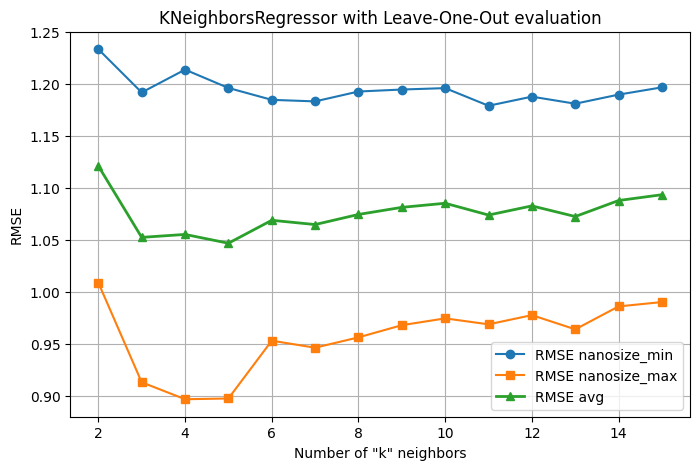

In [ ]:
# k nearest neighbors hyperparameter selection
df = df_no_nan

# Define output columns (targets)
target_cols = ["nanosize_min", "nanosize_max"]

# Outputs: the two columns you want to predict
y = df[target_cols].values

# Inputs: all remaining columns except the targets
X_df = df.drop(columns=target_cols)

# Keep feature names for inspection
feature_cols = X_df.columns.tolist()

# Convert inputs to NumPy arrays if needed
X = X_df.to_numpy(dtype=float)

print("Input features (X):")
for col in feature_cols:
    print(col)

print("\nOutput targets (y):")
print(target_cols)

# Hyperparameter selection "k"
k_values = range(2, 16)
rmse_results = []

loo = LeaveOneOut()

for k in k_values:
    model_min = KNeighborsRegressor(n_neighbors=k, weights='distance')
    model_max = KNeighborsRegressor(n_neighbors=k, weights='distance')

    y_true_min, y_pred_min = [], []
    y_true_max, y_pred_max = [], []

    for train_idx, test_idx in loo.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Train both models per output feature
        model_min.fit(X_train, y_train[:, 0])
        model_max.fit(X_train, y_train[:, 1])

        y_pred_min.append(model_min.predict(X_test)[0])
        y_pred_max.append(model_max.predict(X_test)[0])
        y_true_min.append(y_test[0, 0])
        y_true_max.append(y_test[0, 1])

    # RMSE per target
    rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
    rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
    rmse_avg = np.mean([rmse_min, rmse_max])

    rmse_results.append((k, rmse_min, rmse_max, rmse_avg))
    print(f"K={k:2d}, RMSE_min={rmse_min:.4f}, RMSE_max={rmse_max:.4f}, RMSE_avg={rmse_avg:.4f}")


results_df = pd.DataFrame(rmse_results, columns=['k', 'RMSE_min', 'RMSE_max', 'RMSE_avg'])

# Best "k"
best_row = results_df.loc[results_df['RMSE_avg'].idxmin()]
print("Best k value found:", best_row)

# Plot
plt.figure(figsize=(8,5))
plt.plot(results_df['k'], results_df['RMSE_min'], 'o-', label='RMSE nanosize_min')
plt.plot(results_df['k'], results_df['RMSE_max'], 's-', label='RMSE nanosize_max')
plt.plot(results_df['k'], results_df['RMSE_avg'], '^-', label='RMSE avg', linewidth=2)
plt.xlabel('Number of "k" neighbors')
plt.ylabel('RMSE')
plt.title('KNeighborsRegressor with Leave-One-Out evaluation')
plt.legend()
plt.grid(True)
plt.show()


Input features (X):
pH_min
pH_max
temp_min
temp_max
stirrtime_min
stirrtime_max
extract_min
extract_max
zetapot_min
zetapot_max
Property
Shape
Plant types

Output targets (y):
['nanosize_min', 'nanosize_max']


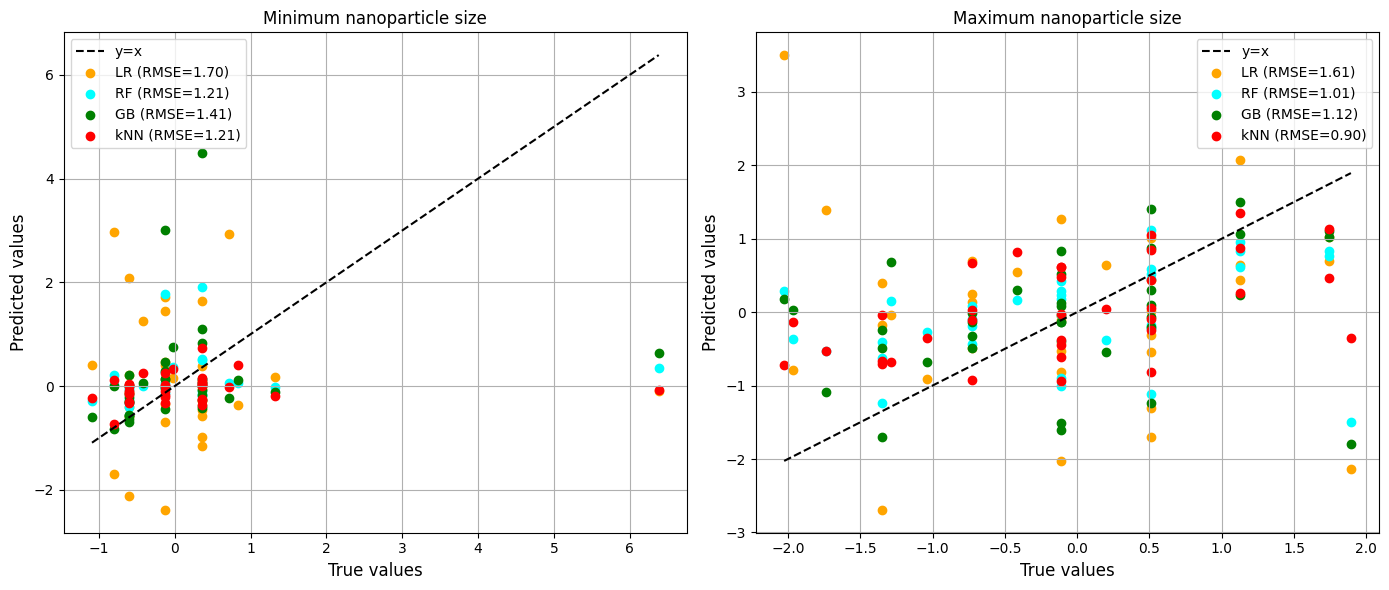

In [ ]:
# Comparison all models with the best hyperparameter selection

# Initial values
df = df_no_nan

# Define output columns (targets)
target_cols = ["nanosize_min", "nanosize_max"]

# Outputs: the two columns you want to predict
y = df[target_cols].values

# Inputs: all remaining columns except the targets
X_df = df.drop(columns=target_cols)

# Keep feature names for inspection
feature_cols = X_df.columns.tolist()

# Convert inputs to NumPy arrays if needed
X = X_df.to_numpy(dtype=float)

print("Input features (X):")
for col in feature_cols:
    print(col)

print("\nOutput targets (y):")
print(target_cols)

loo = LeaveOneOut()

y_true_min, y_true_max = [], []

y_pred_lr = {'min': [], 'max': []}
y_pred_rf_default = {'min': [], 'max': []}
y_pred_rf_opt = {'min': [], 'max': []}
y_pred_gb = {'min': [], 'max': []}
y_pred_knn = {'min': [], 'max': []}

# Use of best "k" value previously found
best_k = 4
knn_min_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')
knn_max_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')

# Leave-One-Out
for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

    # Linear Regression
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    y_pred_lr['min'].append(lr_model.predict(X_test)[0, 0])
    y_pred_lr['max'].append(lr_model.predict(X_test)[0, 1])

    # RandomForest
    rf_opt_min = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_max = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_min.fit(X_train, y_train[:, 0])
    rf_opt_max.fit(X_train, y_train[:, 1])
    y_pred_rf_opt['min'].append(rf_opt_min.predict(X_test)[0])
    y_pred_rf_opt['max'].append(rf_opt_max.predict(X_test)[0])

    # GradientBoosting
    gb_min = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_max = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_min.fit(X_train, y_train[:, 0])
    gb_max.fit(X_train, y_train[:, 1])
    y_pred_gb['min'].append(gb_min.predict(X_test)[0])
    y_pred_gb['max'].append(gb_max.predict(X_test)[0])

    # KNN
    knn_min_model.fit(X_train, y_train[:, 0])
    knn_max_model.fit(X_train, y_train[:, 1])
    y_pred_knn['min'].append(knn_min_model.predict(X_test)[0])
    y_pred_knn['max'].append(knn_max_model.predict(X_test)[0])

# Array conversion
y_true_min = np.array(y_true_min)
y_true_max = np.array(y_true_max)
for d in [y_pred_lr, y_pred_rf_default, y_pred_rf_opt, y_pred_gb, y_pred_knn]:
    d['min'] = np.array(d['min'])
    d['max'] = np.array(d['max'])

# RMSE calculation
rmse_lr_min = np.sqrt(mean_squared_error(y_true_min, y_pred_lr['min']))
rmse_lr_max = np.sqrt(mean_squared_error(y_true_max, y_pred_lr['max']))
rmse_rf_opt_min = np.sqrt(mean_squared_error(y_true_min, y_pred_rf_opt['min']))
rmse_rf_opt_max = np.sqrt(mean_squared_error(y_true_max, y_pred_rf_opt['max']))
rmse_gb_min = np.sqrt(mean_squared_error(y_true_min, y_pred_gb['min']))
rmse_gb_max = np.sqrt(mean_squared_error(y_true_max, y_pred_gb['max']))
rmse_knn_min = np.sqrt(mean_squared_error(y_true_min, y_pred_knn['min']))
rmse_knn_max = np.sqrt(mean_squared_error(y_true_max, y_pred_knn['max']))




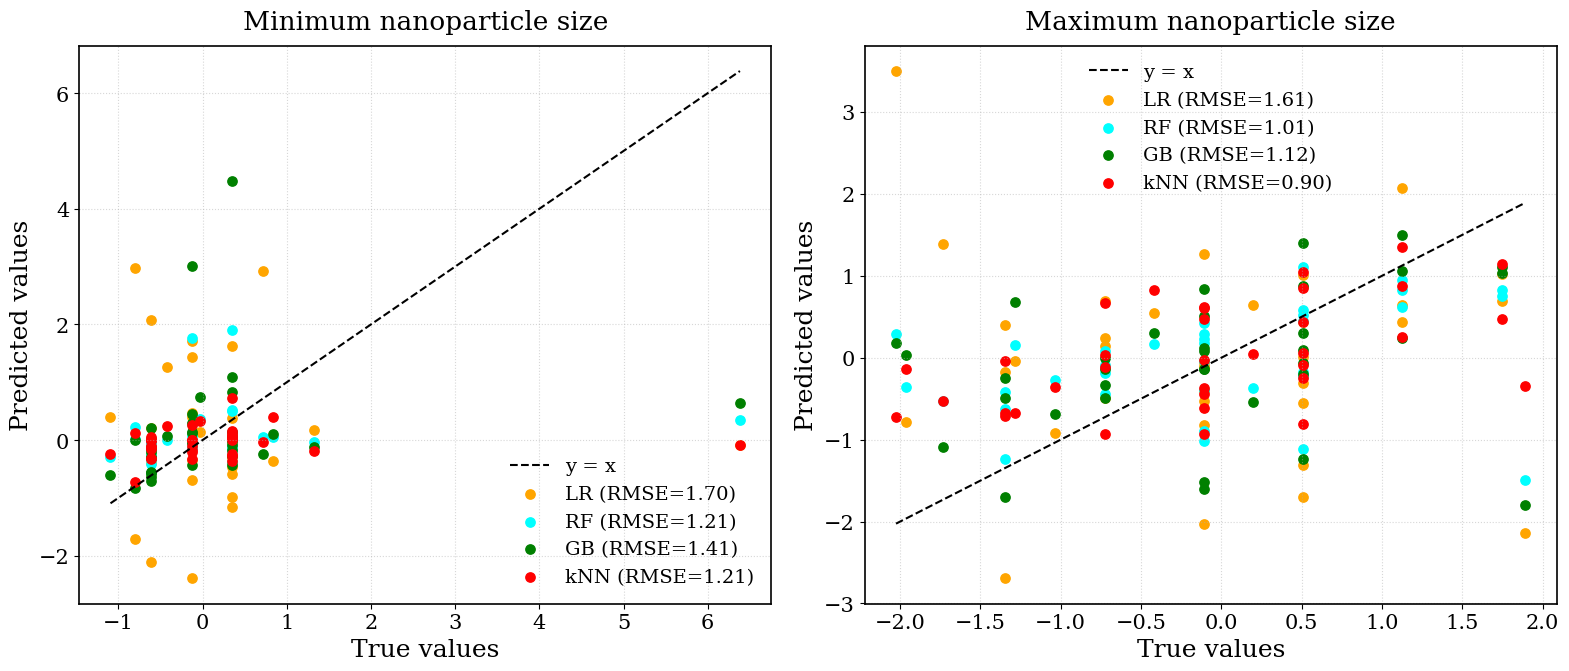

In [ ]:

import matplotlib.pyplot as plt

# Journal-style typography and larger fonts
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 19,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 14,
    'axes.linewidth': 1.2,
    'lines.linewidth': 1.5,
    'savefig.bbox': 'tight',
})

# Figure
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Minimum nanoparticle size
ax = axes[0]

ax.plot(
    [y_true_min.min(), y_true_min.max()],
    [y_true_min.min(), y_true_min.max()],
    'k--', label='y = x'
)
ax.scatter(y_true_min, y_pred_lr['min'],
           color='orange', s=45,
           label=f'LR (RMSE={rmse_lr_min:.2f})')
ax.scatter(y_true_min, y_pred_rf_opt['min'],
           color='cyan', s=45,
           label=f'RF (RMSE={rmse_rf_opt_min:.2f})')
ax.scatter(y_true_min, y_pred_gb['min'],
           color='green', s=45,
           label=f'GB (RMSE={rmse_gb_min:.2f})')
ax.scatter(y_true_min, y_pred_knn['min'],
           color='red', s=45,
           label=f'kNN (RMSE={rmse_knn_min:.2f})')

ax.set_xlabel('True values')
ax.set_ylabel('Predicted values')
ax.set_title('Minimum nanoparticle size', pad=12)
ax.legend(frameon=False)
ax.grid(True, linestyle=':', alpha=0.5)

# Maximum nanoparticle size
ax = axes[1]

ax.plot(
    [y_true_max.min(), y_true_max.max()],
    [y_true_max.min(), y_true_max.max()],
    'k--', label='y = x'
)
ax.scatter(y_true_max, y_pred_lr['max'],
           color='orange', s=45,
           label=f'LR (RMSE={rmse_lr_max:.2f})')
ax.scatter(y_true_max, y_pred_rf_opt['max'],
           color='cyan', s=45,
           label=f'RF (RMSE={rmse_rf_opt_max:.2f})')
ax.scatter(y_true_max, y_pred_gb['max'],
           color='green', s=45,
           label=f'GB (RMSE={rmse_gb_max:.2f})')
ax.scatter(y_true_max, y_pred_knn['max'],
           color='red', s=45,
           label=f'kNN (RMSE={rmse_knn_max:.2f})')

ax.set_xlabel('True values')
ax.set_ylabel('Predicted values')
ax.set_title('Maximum nanoparticle size', pad=12)
ax.legend(frameon=False)
ax.grid(True, linestyle=':', alpha=0.5)

# Improve spacing and export
plt.tight_layout()

plt.savefig('CurveModels.eps', format='eps', dpi=600)
plt.savefig('CurveModels.pdf', format='pdf', bbox_inches='tight')

plt.show()


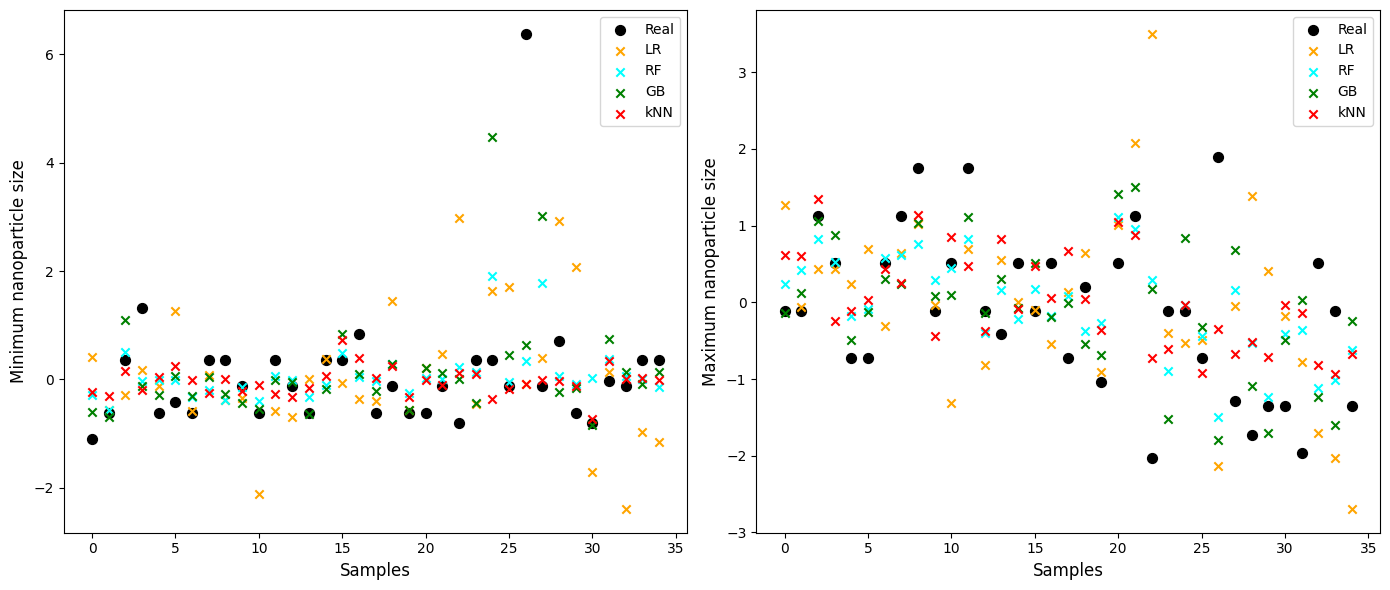

In [ ]:
# Comparison real and predicted values per model using best hyperparameter selection

y_true_min, y_true_max = [], []

# Predictions per model
y_pred_lr = {'min': [], 'max': []}
y_pred_rf_default = {'min': [], 'max': []}
y_pred_rf_opt = {'min': [], 'max': []}
y_pred_gb = {'min': [], 'max': []}
y_pred_knn = {'min': [], 'max': []}

loo = LeaveOneOut()
best_k = 4
knn_min_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')
knn_max_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

    # Linear Regression
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    y_pred_lr['min'].append(lr_model.predict(X_test)[0, 0])
    y_pred_lr['max'].append(lr_model.predict(X_test)[0, 1])


    # Optimized RandomForest
    rf_opt_min = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_max = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_min.fit(X_train, y_train[:, 0])
    rf_opt_max.fit(X_train, y_train[:, 1])
    y_pred_rf_opt['min'].append(rf_opt_min.predict(X_test)[0])
    y_pred_rf_opt['max'].append(rf_opt_max.predict(X_test)[0])

    # GradientBoosting
    gb_min = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_max = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_min.fit(X_train, y_train[:, 0])
    gb_max.fit(X_train, y_train[:, 1])
    y_pred_gb['min'].append(gb_min.predict(X_test)[0])
    y_pred_gb['max'].append(gb_max.predict(X_test)[0])

    # KNN
    knn_min_model.fit(X_train, y_train[:, 0])
    knn_max_model.fit(X_train, y_train[:, 1])
    y_pred_knn['min'].append(knn_min_model.predict(X_test)[0])
    y_pred_knn['max'].append(knn_max_model.predict(X_test)[0])

# Convertir a arrays
y_true_min = np.array(y_true_min)
y_true_max = np.array(y_true_max)
for d in [y_pred_lr, y_pred_rf_default, y_pred_rf_opt, y_pred_gb, y_pred_knn]:
    d['min'] = np.array(d['min'])
    d['max'] = np.array(d['max'])

# RMSE computation
def calc_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_lr_min = calc_rmse(y_true_min, y_pred_lr['min'])
rmse_lr_max = calc_rmse(y_true_max, y_pred_lr['max'])
rmse_rf_opt_min = calc_rmse(y_true_min, y_pred_rf_opt['min'])
rmse_rf_opt_max = calc_rmse(y_true_max, y_pred_rf_opt['max'])
rmse_gb_min = calc_rmse(y_true_min, y_pred_gb['min'])
rmse_gb_max = calc_rmse(y_true_max, y_pred_gb['max'])
rmse_knn_min = calc_rmse(y_true_min, y_pred_knn['min'])
rmse_knn_max = calc_rmse(y_true_max, y_pred_knn['max'])

# Plot
plt.figure(figsize=(14,6))

# nanosize_min
plt.subplot(1,2,1)
plt.scatter(range(len(y_true_min)), y_true_min, color='black', label='Real', s=50)
plt.scatter(range(len(y_pred_lr['min'])), y_pred_lr['min'], color='orange', marker='x', label=f'LR')
plt.scatter(range(len(y_pred_rf_opt['min'])), y_pred_rf_opt['min'], color='cyan', marker='x', label=f'RF')
plt.scatter(range(len(y_pred_gb['min'])), y_pred_gb['min'], color='green', marker='x', label=f'GB')
plt.scatter(range(len(y_pred_knn['min'])), y_pred_knn['min'], color='red', marker='x', label=f'kNN')
plt.xlabel('Samples', fontname='Calibri', fontsize=12)
plt.ylabel('Minimum nanoparticle size', fontname='Calibri', fontsize=12)
plt.legend()

# nanosize_max
plt.subplot(1,2,2)
plt.scatter(range(len(y_true_max)), y_true_max, color='black', label='Real', s=50)
plt.scatter(range(len(y_pred_lr['max'])), y_pred_lr['max'], color='orange', marker='x', label=f'LR')
plt.scatter(range(len(y_pred_rf_opt['max'])), y_pred_rf_opt['max'], color='cyan', marker='x', label=f'RF')
plt.scatter(range(len(y_pred_gb['max'])), y_pred_gb['max'], color='green', marker='x', label=f'GB')
plt.scatter(range(len(y_pred_knn['max'])), y_pred_knn['max'], color='red', marker='x', label=f'kNN')
plt.xlabel('Samples', fontname='Calibri', fontsize=12)
plt.ylabel('Maximum nanoparticle size', fontname='Calibri', fontsize=12)
plt.legend()

plt.tight_layout()

plt.savefig("model_comparison.eps", format='eps', dpi=300)
plt.show()


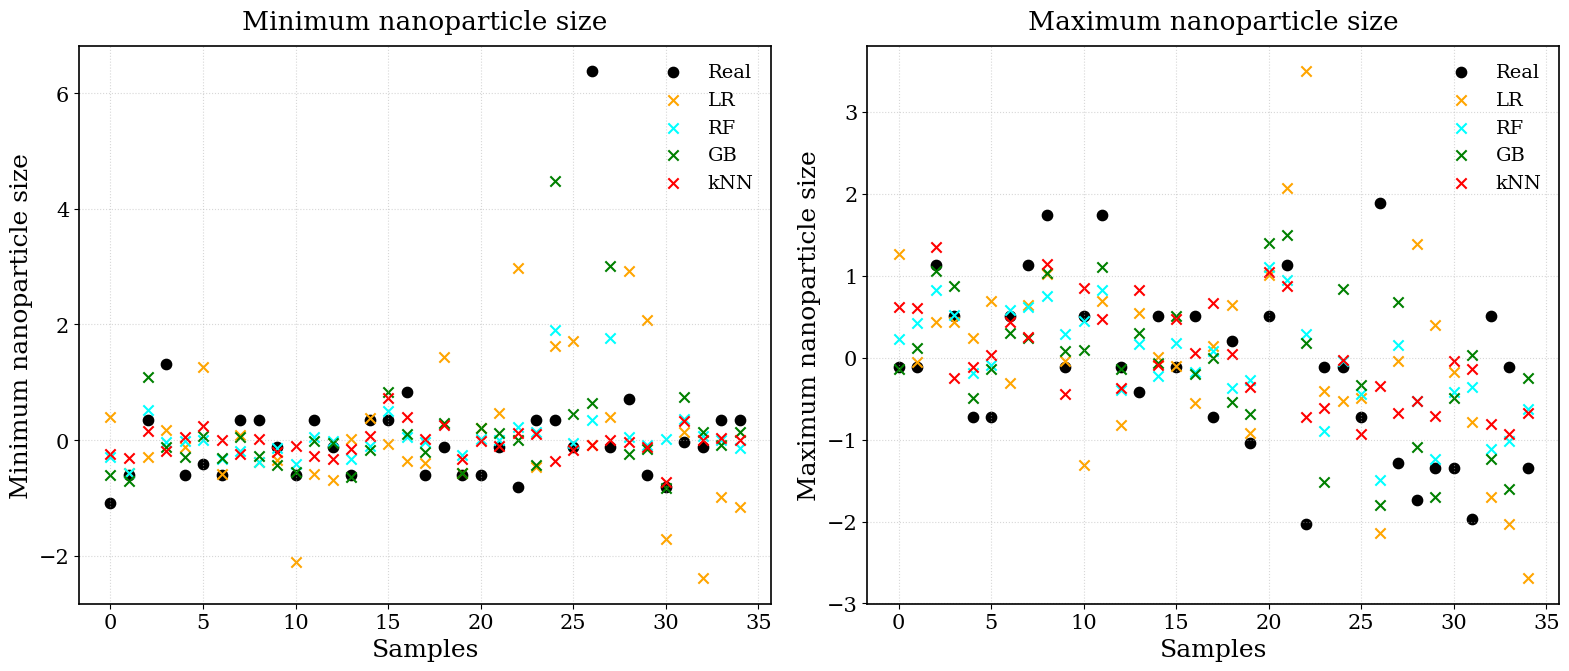

In [ ]:

import matplotlib.pyplot as plt

# Journal-style typography: all font sizes increased by 2 pt
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 19,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 14,
    'axes.linewidth': 1.2,
    'lines.linewidth': 1.5,
    'savefig.bbox': 'tight',
})

# Figure
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Minimum nanoparticle size
ax = axes[0]
ax.scatter(range(len(y_true_min)), y_true_min,
           color='black', label='Real', s=55)
ax.scatter(range(len(y_pred_lr['min'])), y_pred_lr['min'],
           color='orange', marker='x', label='LR', s=55)
ax.scatter(range(len(y_pred_rf_opt['min'])), y_pred_rf_opt['min'],
           color='cyan', marker='x', label='RF', s=55)
ax.scatter(range(len(y_pred_gb['min'])), y_pred_gb['min'],
           color='green', marker='x', label='GB', s=55)
ax.scatter(range(len(y_pred_knn['min'])), y_pred_knn['min'],
           color='red', marker='x', label='kNN', s=55)

ax.set_xlabel('Samples')
ax.set_ylabel('Minimum nanoparticle size')
ax.set_title('Minimum nanoparticle size', pad=12)
ax.legend(frameon=False)
ax.grid(True, linestyle=':', alpha=0.5)

# Maximum nanoparticle size
ax = axes[1]
ax.scatter(range(len(y_true_max)), y_true_max,
           color='black', label='Real', s=55)
ax.scatter(range(len(y_pred_lr['max'])), y_pred_lr['max'],
           color='orange', marker='x', label='LR', s=55)
ax.scatter(range(len(y_pred_rf_opt['max'])), y_pred_rf_opt['max'],
           color='cyan', marker='x', label='RF', s=55)
ax.scatter(range(len(y_pred_gb['max'])), y_pred_gb['max'],
           color='green', marker='x', label='GB', s=55)
ax.scatter(range(len(y_pred_knn['max'])), y_pred_knn['max'],
           color='red', marker='x', label='kNN', s=55)

ax.set_xlabel('Samples')
ax.set_ylabel('Maximum nanoparticle size')
ax.set_title('Maximum nanoparticle size', pad=12)
ax.legend(frameon=False)
ax.grid(True, linestyle=':', alpha=0.5)

# Layout and export
plt.tight_layout()

plt.savefig('model_comparison.eps', format='eps', dpi=600)
plt.savefig('model_comparison.pdf', format='pdf', bbox_inches='tight')

plt.show()


In [ ]:
"""
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# X_test: held-out input features as a DataFrame
# Use the exact fitted models and test data from your workflow.

models_min = {
    'LR': lr_min,
    'RF': rf_opt_min,
    'GB': gb_min,
    'kNN': knn_min
}

models_max = {
    'LR': lr_max,
    'RF': rf_opt_max,
    'GB': gb_max,
    'kNN': knn_max
}

def calculate_importance(models, X_test, y_test):
    results = {}

    for name, model in models.items():
        result = permutation_importance(
            model,
            X_test,
            y_test,
            scoring='neg_root_mean_squared_error',
            n_repeats=30,
            random_state=42,
            n_jobs=-1
        )

        results[name] = pd.Series(
            result.importances_mean,
            index=X_test.columns
        ).sort_values(ascending=False)

    return results

importance_min = calculate_importance(
    models_min, X_test, y_test_min
)

importance_max = calculate_importance(
    models_max, X_test, y_test_max
)

# Plot feature importance for each model
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, importance) in zip(
    axes.flat, importance_min.items()
):
    importance.sort_values().plot.barh(ax=ax)
    ax.set_title(f'Minimum size: {name}')
    ax.set_xlabel('Increase in RMSE after permutation')
    ax.grid(axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('importance_minimum_size.pdf', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, importance) in zip(
    axes.flat, importance_max.items()
):
    importance.sort_values().plot.barh(ax=ax)
    ax.set_title(f'Maximum size: {name}')
    ax.set_xlabel('Increase in RMSE after permutation')
    ax.grid(axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('importance_maximum_size.pdf', bbox_inches='tight')
plt.show()

# Export numerical importance values
pd.DataFrame(importance_min).to_csv(
    'importance_minimum_size.csv'
)
pd.DataFrame(importance_max).to_csv(
    'importance_maximum_size.csv'
)
"""

NameError: name 'lr_min' is not defined